# IEI097 · Actividad 2.12 — Redes neuronales: MLP y MLflow

**Estudiante:** Sebastián
**SEED:** 20217700
**Asignatura:** IEI097 Minería de Datos · Unidad II
**Conjunto de datos:** Breast Cancer Wisconsin, 569 registros y 30 variables

El entregable es este notebook ejecutado. Cada entrenamiento queda registrado en MLflow con sus parámetros, métricas, curva de pérdida y matriz de confusión. Los números que aparecen en el texto son los que produjo esta ejecución.

El número de lista se escribe con puntos y guion, pero `random_state` exige un entero. Uso 20217700, sin el dígito verificador K: es el mismo número en el formato que acepta scikit-learn.

## Cómo ejecutarlo

1. Abrir el notebook en Colab y ejecutar todas las celdas en orden.
2. Tener el secreto `NGROK_AUTHTOKEN` disponible para el notebook.
3. La sección 4 levanta el servidor de MLflow, publica el puerto con ngrok e imprime la URL de la interfaz.

Fuera de Colab funciona igual si están instalados `mlflow`, `pyngrok` y las librerías de siempre. Si no hay token de ngrok, el notebook continúa y la interfaz queda solo en la máquina local.

## 1. Entorno y semilla

La semilla fija tres cosas: la partición entrenamiento/prueba, los pesos iniciales y el orden en que la red recorre los datos. Con la misma semilla y las mismas versiones, el resultado se repite. La semilla no mejora el modelo, solo lo hace repetible.

El entorno también forma parte del experimento: si cambia la versión de scikit-learn, el resultado puede cambiar aunque la semilla sea la misma. Por eso las versiones se imprimen y quedan en el registro.

In [1]:
# En Colab instala lo que la imagen no trae. Fuera de Colab no hace nada.
import sys

if "google.colab" in sys.modules:
    !pip install -q "mlflow==3.1.4" pyngrok kagglehub

In [2]:
import logging
import os
import random
import subprocess
import sys
import time
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import requests
import sklearn
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
logging.getLogger("mlflow").setLevel(logging.WARNING)

SEED = 20217700
random.seed(SEED)
np.random.seed(SEED)

print("pandas", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("mlflow", mlflow.__version__)
print("semilla", SEED)

pandas 2.3.3
scikit-learn 1.9.1
mlflow 3.1.4
semilla 20217700


## 2. Datos

El conjunto se descarga desde Kaggle cuando hay credenciales disponibles. Si la descarga no está disponible, el notebook usa la copia que acompaña al repositorio, así la ejecución no depende de la red.

El archivo original trae 33 columnas: `id`, `diagnosis`, 30 mediciones y una columna vacía llamada `Unnamed: 32`. `id` identifica al paciente y la columna vacía es un residuo del archivo, así que ambas se eliminan. La etiqueta se codifica como 1 para maligno (la clase de interés) y 0 para benigno.

In [3]:
def descargar_dataset():
    """Baja el dataset desde Kaggle y devuelve la ruta del CSV."""
    import kagglehub

    carpeta = Path(kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data"))
    return next(carpeta.rglob("*.csv"))


def buscar_copia_local():
    """Copia del CSV incluida en el repositorio."""
    candidatas = [Path("datos/breast_cancer.csv"), Path("breast_cancer.csv")]
    candidatas += sorted(Path(".").glob("*/datos/breast_cancer.csv"))
    return next((c for c in candidatas if c.exists()), None)


try:
    ruta = descargar_dataset()
except Exception:
    ruta = buscar_copia_local()

datos = pd.read_csv(ruta)
print("archivo:", ruta)
print("shape inicial:", datos.shape)
datos.info()

archivo: datos\breast_cancer.csv
shape inicial: (569, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se            

In [4]:
print("nulos por columna:")
print(datos.isna().sum().sort_values(ascending=False).head(3).to_string())

datos = datos.drop(columns=["id", "Unnamed: 32"])
datos["diagnosis"] = datos["diagnosis"].map({"M": 1, "B": 0})
print()
print("shape después de limpiar:", datos.shape)
print()
print("clases:")
print(datos["diagnosis"].value_counts().to_string())
print()
print("escala de tres variables:")
resumen = datos[["radius_mean", "area_mean", "smoothness_mean"]].agg(["min", "max"])
resumen.loc["rango"] = resumen.loc["max"] - resumen.loc["min"]
print(resumen.to_string())

nulos por columna:
Unnamed: 32    569
id               0
diagnosis        0

shape después de limpiar: (569, 31)

clases:
diagnosis
0    357
1    212

escala de tres variables:
       radius_mean  area_mean  smoothness_mean
min          6.981      143.5          0.05263
max         28.110     2501.0          0.16340
rango       21.129     2357.5          0.11077


El archivo queda con 569 filas y 31 columnas: 30 variables y la etiqueta. `Unnamed: 32` está vacía en las 569 filas.

Clases: 357 benignos (62,7 %) y 212 malignos (37,3 %). La clase de interés es la maligna, que además es la minoritaria.

La escala no es comparable entre variables. `area_mean` va de 143,5 a 2.501,0, con un rango de 2.357,5. `radius_mean` va de 6,981 a 28,110, con un rango de 21,129. `smoothness_mean` va de 0,0526 a 0,1634, con un rango de 0,1108. El rango de `area_mean` es unas 21.283 veces el de `smoothness_mean` y 111,6 veces el de `radius_mean`. Sin escalar, esa diferencia pesa en cada suma ponderada de la red.

## 3. Partición estratificada

La partición se hace una sola vez y se mantiene fija en todos los experimentos. Así, cualquier diferencia entre ejecuciones se debe al cambio que se introduce y no a un reparto distinto de los datos.

`stratify=y` conserva la proporción de clases en ambos conjuntos. Con 114 casos de prueba, cada caso vale 0,88 puntos porcentuales de exactitud, un detalle que conviene tener a la vista al comparar.

In [5]:
X = datos.drop(columns="diagnosis")
y = datos["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print("train:", X_train.shape, " test:", X_test.shape)
print(f"proporción maligna en train: {y_train.mean():.4f}")
print(f"proporción maligna en test:  {y_test.mean():.4f}")
print(f"malignos en train: {int(y_train.sum())} de {len(y_train)}")
print(f"malignos en test:  {int(y_test.sum())} de {len(y_test)}")

train: (455, 30)  test: (114, 30)
proporción maligna en train: 0.3736
proporción maligna en test:  0.3684
malignos en train: 170 de 455
malignos en test:  42 de 114


## 4. MLflow en Colab

MLflow tiene tres piezas en este laboratorio. El servidor de seguimiento guarda los experimentos en una base SQLite. El notebook es el cliente que le envía cada ejecución. El túnel de ngrok publica el puerto del servidor para abrir la interfaz desde el navegador, porque Colab no expone sus puertos hacia afuera.

El servidor se levanta en segundo plano y se espera a que responda antes de seguir. Si ya estaba en marcha, se reutiliza.

Mientras el túnel esté abierto, la interfaz es accesible desde Internet sin contraseña y con la validación de hosts desactivada. Es aceptable solo en este laboratorio: la URL es temporal y los datos son públicos. No se registra información sensible y el túnel se cierra al final.

In [6]:
EN_COLAB = "google.colab" in sys.modules
PUERTO = int(os.environ.get("MLFLOW_PORT", 5000))
TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI", f"http://127.0.0.1:{PUERTO}")


def esperar_servidor(url, segundos=90):
    """Devuelve True cuando el servidor responde /health."""
    for _ in range(segundos):
        try:
            if requests.get(f"{url}/health", timeout=2).ok:
                return True
        except requests.RequestException:
            pass
        time.sleep(1)
    return False


def levantar_servidor():
    """Arranca el servidor de seguimiento con SQLite si no está activo."""
    if esperar_servidor(TRACKING_URI, 2):
        return "ya estaba en marcha"
    entorno = dict(
        os.environ,
        MLFLOW_SERVER_ALLOWED_HOSTS="*",
        MLFLOW_SERVER_CORS_ALLOWED_ORIGINS="*",
    )
    subprocess.Popen(
        [
            sys.executable, "-m", "mlflow", "server",
            "--backend-store-uri", "sqlite:///mlflow.db",
            "--host", "127.0.0.1", "--port", str(PUERTO),
        ],
        env=entorno,
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
    )
    if not esperar_servidor(TRACKING_URI):
        raise RuntimeError("MLflow no respondió en 90 segundos")
    return "iniciado"


def abrir_tunel():
    """Publica el puerto del servidor y devuelve la URL pública."""
    from pyngrok import ngrok

    token = os.environ.get("NGROK_AUTHTOKEN")
    if not token and EN_COLAB:
        from google.colab import userdata

        token = userdata.get("NGROK_AUTHTOKEN")
    if not token:
        return "sin token de ngrok: la interfaz queda solo en local"
    try:
        ngrok.set_auth_token(token)
    except Exception:
        pass  # el token ya estaba guardado en la configuración de ngrok
    ngrok.kill()
    return ngrok.connect(PUERTO).public_url


print("Servidor:", levantar_servidor())
print("MLflow UI:", abrir_tunel())

mlflow.set_tracking_uri(TRACKING_URI)
EXPERIMENTO = "IEI097-L2.12-espinoza"
mlflow.set_experiment(EXPERIMENTO)
print("Experimento:", EXPERIMENTO)

Servidor: iniciado


MLflow UI: https://request-remix-obsessed.ngrok-free.dev


Experimento: IEI097-L2.12-espinoza


## 5. Experimentos controlados

**Hipótesis antes de ejecutar.** Espero que el run B supere al run A. Sin escalar, `area_mean` domina la suma ponderada frente a `smoothness_mean`, porque su rango es más de 21.000 veces mayor. El descenso del gradiente se mueve entonces casi solo por las variables grandes, la superficie de pérdida queda mal condicionada y la red necesita más épocas para acercarse al mínimo. Con estandarización todas las variables entran con media 0 y desviación 1, así que espero más exactitud, más sensibilidad en la clase maligna y una convergencia más rápida.

Los cuatro runs base cambian una cosa a la vez y mantienen la semilla y la partición. Se agregan dos runs opcionales sobre la configuración C para ver si la regularización y la tasa de aprendizaje mueven el resultado.

In [7]:
def correr_experimento(nombre, fase, capas, activacion, escalar, semilla,
                       alpha=0.0001, max_iter=200, lr=0.001):
    """Entrena una configuración y registra parámetros, métricas y artefactos."""
    modelo = MLPClassifier(
        hidden_layer_sizes=capas,
        activation=activacion,
        alpha=alpha,
        max_iter=max_iter,
        learning_rate_init=lr,
        random_state=semilla,
    )
    pasos = [("escalado", StandardScaler()), ("mlp", modelo)] if escalar else [("mlp", modelo)]
    tuberia = Pipeline(pasos)
    tuberia.fit(X_train, y_train)
    red = tuberia.named_steps["mlp"]

    pred_train = tuberia.predict(X_train)
    pred_test = tuberia.predict(X_test)
    metricas = {
        "accuracy_train": accuracy_score(y_train, pred_train),
        "accuracy_test": accuracy_score(y_test, pred_test),
        "recall_maligno": recall_score(y_test, pred_test, pos_label=1),
        "f1_maligno": f1_score(y_test, pred_test, pos_label=1),
        "n_iter": float(red.n_iter_),
    }

    with mlflow.start_run(run_name=nombre):
        mlflow.set_tag("fase", fase)
        mlflow.log_params({
            "capas": str(capas),
            "activacion": activacion,
            "alpha": alpha,
            "max_iter": max_iter,
            "learning_rate_init": lr,
            "random_state": semilla,
            "escalado": escalar,
            "semilla_particion": SEED,
        })
        mlflow.log_metrics(metricas)
        for epoca, perdida in enumerate(red.loss_curve_):
            mlflow.log_metric("train_loss", perdida, step=epoca)

        figura, eje = plt.subplots(figsize=(4.2, 3.6))
        ConfusionMatrixDisplay.from_predictions(
            y_test, pred_test,
            display_labels=["Benigno", "Maligno"],
            cmap="Greens", colorbar=False, ax=eje,
        )
        eje.set_title(f"Matriz de confusión · {nombre}")
        figura.tight_layout()
        mlflow.log_figure(figura, "matriz_confusion.png")
        plt.close(figura)

        figura, eje = plt.subplots(figsize=(5.2, 3.4))
        eje.plot(red.loss_curve_, color="#004F45")
        eje.set_xlabel("época")
        eje.set_ylabel("pérdida")
        eje.set_title(f"Pérdida de entrenamiento · {nombre}")
        figura.tight_layout()
        mlflow.log_figure(figura, "curva_perdida.png")
        plt.close(figura)

    print(
        f"{nombre}: exactitud test {metricas['accuracy_test']:.4f} · "
        f"recall maligno {metricas['recall_maligno']:.4f} · "
        f"F1 {metricas['f1_maligno']:.4f} · iteraciones {int(metricas['n_iter'])}"
    )
    return metricas

In [8]:
metricas_A = correr_experimento(
    "A_sin_escalado_30_relu", "experimentos",
    capas=(30,), activacion="relu", escalar=False, semilla=SEED,
)

🏃 View run A_sin_escalado_30_relu at: http://127.0.0.1:5050/#/experiments/1/runs/dd32b9c3b7414fdb8e106b67e62d3e10
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/1
A_sin_escalado_30_relu: exactitud test 0.9561 · recall maligno 0.9048 · F1 0.9383 · iteraciones 198


**Run A, sin escalado, 30 neuronas ReLU.** Exactitud de 95,6 % en prueba y sensibilidad de 90,5 %: deja pasar 4 tumores malignos de 42 y marca 1 benigno como maligno. La pérdida parte en 20,15 y termina en 0,15 después de 198 épocas. Esa magnitud no se puede comparar con la de los runs escalados, porque las entradas tienen otro tamaño; lo que se compara es la forma de la curva. La exactitud en entrenamiento (94,3 %) es menor que en prueba, así que el modelo todavía no ajusta del todo ni siquiera los datos que vio.

In [9]:
metricas_B = correr_experimento(
    "B_escalado_30_relu", "experimentos",
    capas=(30,), activacion="relu", escalar=True, semilla=SEED,
)

🏃 View run B_escalado_30_relu at: http://127.0.0.1:5050/#/experiments/1/runs/951ba52434004f7f9316a38094519876
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/1
B_escalado_30_relu: exactitud test 0.9912 · recall maligno 0.9762 · F1 0.9880 · iteraciones 200


**Run B, mismo modelo con estandarización.** Sube a 99,1 % de exactitud y 97,6 % de sensibilidad: queda 1 falso negativo y ningún falso positivo. Son 3,5 puntos de exactitud y 7,1 puntos de sensibilidad, es decir, 4 malignos menos clasificados como benignos. La pérdida baja de 0,59 a 0,04 y la exactitud en entrenamiento llega a 98,9 %. La hipótesis se cumple: con las variables en la misma escala, la red aprovecha mejor las 30 mediciones. La comparación directa de la pérdida inicial entre A y B no sirve, porque la escala de las entradas cambia la magnitud de la pérdida.

In [10]:
metricas_C = correr_experimento(
    "C_escalado_64_32_relu", "experimentos",
    capas=(64, 32), activacion="relu", escalar=True, semilla=SEED,
)

🏃 View run C_escalado_64_32_relu at: http://127.0.0.1:5050/#/experiments/1/runs/a4397fb136624fc9a3630fc108a7a319
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/1
C_escalado_64_32_relu: exactitud test 0.9912 · recall maligno 0.9762 · F1 0.9880 · iteraciones 200


**Run C, dos capas ocultas de 64 y 32 neuronas.** En prueba queda igual que B: 99,1 % de exactitud, 97,6 % de sensibilidad, 1 falso negativo. La diferencia está en entrenamiento, que sube de 98,9 % a 100,0 %. La capacidad extra se gastó en memorizar el conjunto de entrenamiento y no se tradujo en ninguna mejora sobre los 114 casos de prueba. Con una diferencia de 0,0 puntos, no hay evidencia de que más capas y neuronas mejoren el resultado.

In [11]:
metricas_D = correr_experimento(
    "D_escalado_64_32_tanh", "experimentos",
    capas=(64, 32), activacion="tanh", escalar=True, semilla=SEED,
)

🏃 View run D_escalado_64_32_tanh at: http://127.0.0.1:5050/#/experiments/1/runs/26f481a821b94a4bb7a2d93b4efa68b1
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/1
D_escalado_64_32_tanh: exactitud test 0.9737 · recall maligno 0.9524 · F1 0.9639 · iteraciones 200


**Run D, la misma arquitectura con activación tanh.** Baja a 97,4 % de exactitud y 95,2 % de sensibilidad: 2 falsos negativos y 1 falso positivo. La pérdida termina en 0,015, más baja que la de C (0,006) en el mismo orden de magnitud. El cambio de activación sí mueve el resultado, y en este caso lo empeora: dos casos de prueba de diferencia. Tanh no es peor en general; con esta partición y esta semilla, la red con ReLU clasifica mejor el borde entre benigno y maligno.

In [12]:
metricas_E = correr_experimento(
    "E_alpha_0.5", "experimentos",
    capas=(64, 32), activacion="relu", escalar=True, semilla=SEED, alpha=0.5,
)
metricas_F = correr_experimento(
    "F_lr_0.0005", "experimentos",
    capas=(64, 32), activacion="relu", escalar=True, semilla=SEED, lr=0.0005,
)

🏃 View run E_alpha_0.5 at: http://127.0.0.1:5050/#/experiments/1/runs/ea25745912114a6ab827ac63c7e6bf6a
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/1
E_alpha_0.5: exactitud test 0.9912 · recall maligno 0.9762 · F1 0.9880 · iteraciones 200


🏃 View run F_lr_0.0005 at: http://127.0.0.1:5050/#/experiments/1/runs/008940e513e94b4bb431b8c6a4979aa5
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/1
F_lr_0.0005: exactitud test 0.9912 · recall maligno 0.9762 · F1 0.9880 · iteraciones 200


**Runs E y F, regularización y tasa de aprendizaje.** E multiplica por 5.000 el valor de `alpha` (de 0,0001 a 0,5) y F reduce a la mitad la tasa de aprendizaje. Los dos quedan igual que C en prueba (99,1 % de exactitud, 97,6 % de sensibilidad), y en entrenamiento bajan de 100,0 % a 99,1 %. La regularización más fuerte frena la memorización, pero no cambia ninguna decisión sobre el conjunto de prueba. La tasa de aprendizaje tampoco mueve el resultado en 200 épocas. Con 114 casos, estas diferencias no alcanzan para distinguir configuraciones.

## 6. Semillas y réplica

La configuración C se repite con cinco semillas del modelo: `SEED`, `SEED+1` hasta `SEED+4`. La partición queda fija, así que el único cambio es la inicialización de los pesos y el orden de las muestras.

Después se repite una vez más con `SEED` y la etiqueta `replica`. Esa ejecución debe coincidir exactamente con el run C: misma partición, misma semilla y mismas versiones. Si no coincide, quedó alguna fuente de aleatoriedad sin fijar.

In [13]:
resultados_semillas = {}
for i in range(5):
    semilla = SEED + i
    resultados_semillas[semilla] = correr_experimento(
        f"C_semilla_{semilla}", "semillas",
        capas=(64, 32), activacion="relu", escalar=True, semilla=semilla,
    )

replica = correr_experimento(
    "C_replica_20217700", "replica",
    capas=(64, 32), activacion="relu", escalar=True, semilla=SEED,
)

🏃 View run C_semilla_20217700 at: http://127.0.0.1:5050/#/experiments/1/runs/101a6e667bbb4b9da88a33b60200ffee
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/1
C_semilla_20217700: exactitud test 0.9912 · recall maligno 0.9762 · F1 0.9880 · iteraciones 200


🏃 View run C_semilla_20217701 at: http://127.0.0.1:5050/#/experiments/1/runs/405e2f68cb65449ebb5303dea050f681
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/1
C_semilla_20217701: exactitud test 0.9912 · recall maligno 0.9762 · F1 0.9880 · iteraciones 198


🏃 View run C_semilla_20217702 at: http://127.0.0.1:5050/#/experiments/1/runs/1d1e44260441494298c546e4bd867a2c
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/1
C_semilla_20217702: exactitud test 0.9825 · recall maligno 0.9524 · F1 0.9756 · iteraciones 198


🏃 View run C_semilla_20217703 at: http://127.0.0.1:5050/#/experiments/1/runs/61196563f33b4ebbbf2dcd4a956f8403
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/1
C_semilla_20217703: exactitud test 0.9912 · recall maligno 0.9762 · F1 0.9880 · iteraciones 176


🏃 View run C_semilla_20217704 at: http://127.0.0.1:5050/#/experiments/1/runs/0c9ef2a5ad9b43938302f36dd1ef09a3
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/1
C_semilla_20217704: exactitud test 0.9825 · recall maligno 0.9524 · F1 0.9756 · iteraciones 176


🏃 View run C_replica_20217700 at: http://127.0.0.1:5050/#/experiments/1/runs/d9085a41e05444a982eaf2ce5fafeb8c
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/1
C_replica_20217700: exactitud test 0.9912 · recall maligno 0.9762 · F1 0.9880 · iteraciones 200


In [14]:
tabla_semillas = pd.DataFrame(resultados_semillas).T
tabla_semillas.index.name = "semilla"
print(tabla_semillas[["accuracy_test", "recall_maligno", "f1_maligno", "n_iter"]].round(4).to_string())

for metrica in ("accuracy_test", "recall_maligno"):
    valores = tabla_semillas[metrica]
    print(
        f"\n{metrica}: mínimo {valores.min():.4f} · máximo {valores.max():.4f} · "
        f"rango {valores.max() - valores.min():.4f}"
    )

print("\nréplica frente a C:")
for nombre in ("accuracy_train", "accuracy_test", "recall_maligno", "f1_maligno", "n_iter"):
    print(f"  {nombre}: C {metricas_C[nombre]:.6f} · réplica {replica[nombre]:.6f}")

          accuracy_test  recall_maligno  f1_maligno  n_iter
semilla                                                    
20217700         0.9912          0.9762      0.9880   200.0
20217701         0.9912          0.9762      0.9880   198.0
20217702         0.9825          0.9524      0.9756   198.0
20217703         0.9912          0.9762      0.9880   176.0
20217704         0.9825          0.9524      0.9756   176.0

accuracy_test: mínimo 0.9825 · máximo 0.9912 · rango 0.0088

recall_maligno: mínimo 0.9524 · máximo 0.9762 · rango 0.0238

réplica frente a C:
  accuracy_train: C 1.000000 · réplica 1.000000
  accuracy_test: C 0.991228 · réplica 0.991228
  recall_maligno: C 0.976190 · réplica 0.976190
  f1_maligno: C 0.987952 · réplica 0.987952
  n_iter: C 200.000000 · réplica 200.000000


**Variabilidad entre semillas.** La exactitud en prueba toma dos valores: 99,1 % en tres semillas y 98,2 % en dos. El mínimo es 0,9825, el máximo 0,9912 y el rango 0,0088, es decir, 0,9 puntos porcentuales, que equivalen a un caso de prueba. La sensibilidad de la clase maligna va de 0,9524 a 0,9762, con un rango de 0,0238, o 2,4 puntos, que equivalen a un falso negativo.

**Réplica.** El run C y su réplica coinciden hasta el sexto decimal en exactitud, sensibilidad, F1 e iteraciones. La única fuente de aleatoriedad era la semilla del modelo, y estaba fijada.

**Comparación con las configuraciones.** La diferencia entre B y C es de 0,0 puntos en prueba, menor que el rango entre semillas. La diferencia entre B y D es de 1,8 puntos de exactitud y 2,4 de sensibilidad, del mismo tamaño que el rango entre semillas. Con una sola partición y 114 casos, solo el escalado produce una diferencia claramente mayor que el ruido. Las demás no se pueden separar de la variación de la semilla.

## 7. Análisis y exportación de la evidencia

`mlflow.search_runs()` devuelve todas las ejecuciones del experimento como un DataFrame. Se ordenan por sensibilidad de la clase maligna, se seleccionan las columnas que importan y se guardan en `runs.csv`.

Las dos figuras que siguen se guardan en `evidencias/` y sirven de apoyo a las capturas de la interfaz. La primera compara el recall de las 12 ejecuciones; el eje horizontal se recorta en 0,90 para que se vean las diferencias. La segunda superpone la pérdida de entrenamiento de A y C.

In [15]:
Path("evidencias").mkdir(exist_ok=True)

experimento = mlflow.get_experiment_by_name(EXPERIMENTO)
ejecuciones = mlflow.search_runs(experiment_ids=[experimento.experiment_id])

columnas = [
    "run_id",
    "tags.mlflow.runName",
    "tags.fase",
    "params.capas",
    "params.activacion",
    "params.escalado",
    "params.alpha",
    "params.learning_rate_init",
    "params.random_state",
    "metrics.accuracy_train",
    "metrics.accuracy_test",
    "metrics.recall_maligno",
    "metrics.f1_maligno",
    "metrics.n_iter",
    "start_time",
]
tabla = ejecuciones[columnas].sort_values("metrics.recall_maligno", ascending=False)
tabla.to_csv("runs.csv", index=False)

print("ejecuciones registradas:", len(tabla))
print("runs.csv guardado")
print()
print(
    tabla[
        ["tags.mlflow.runName", "tags.fase", "metrics.accuracy_test", "metrics.recall_maligno"]
    ].to_string(index=False)
)

ejecuciones registradas: 12
runs.csv guardado

   tags.mlflow.runName    tags.fase  metrics.accuracy_test  metrics.recall_maligno
    C_replica_20217700      replica               0.991228                0.976190
    C_semilla_20217703     semillas               0.991228                0.976190
    C_semilla_20217700     semillas               0.991228                0.976190
    C_semilla_20217701     semillas               0.991228                0.976190
 C_escalado_64_32_relu experimentos               0.991228                0.976190
    B_escalado_30_relu experimentos               0.991228                0.976190
           F_lr_0.0005 experimentos               0.991228                0.976190
           E_alpha_0.5 experimentos               0.991228                0.976190
    C_semilla_20217702     semillas               0.982456                0.952381
    C_semilla_20217704     semillas               0.982456                0.952381
 D_escalado_64_32_tanh experimentos     

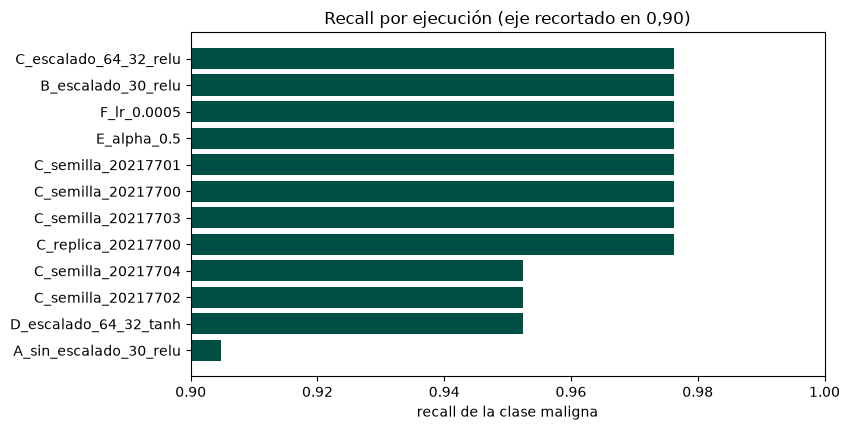

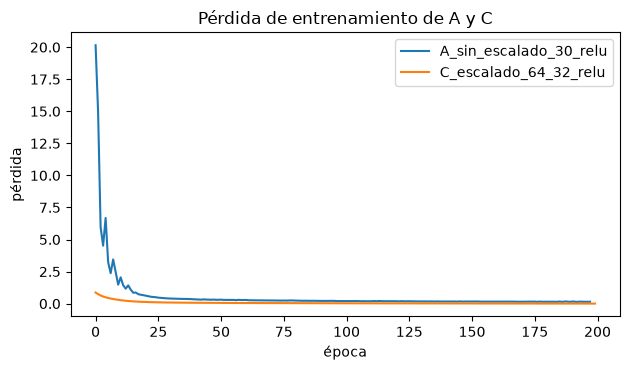

In [16]:
figura, eje = plt.subplots(figsize=(8.6, 4.4))
orden = tabla.sort_values("metrics.recall_maligno")
eje.barh(orden["tags.mlflow.runName"], orden["metrics.recall_maligno"], color="#004F45")
eje.set_xlim(0.90, 1.0)
eje.set_xlabel("recall de la clase maligna")
eje.set_title("Recall por ejecución (eje recortado en 0,90)")
figura.tight_layout()
figura.savefig("evidencias/comparacion_recall.png", dpi=150)
plt.show()

cliente = mlflow.tracking.MlflowClient()
figura, eje = plt.subplots(figsize=(6.4, 3.8))
for nombre in ("A_sin_escalado_30_relu", "C_escalado_64_32_relu"):
    corrida = tabla[tabla["tags.mlflow.runName"] == nombre].iloc[0]
    historia = cliente.get_metric_history(corrida["run_id"], "train_loss")
    eje.plot([punto.step for punto in historia], [punto.value for punto in historia], label=nombre)
eje.set_xlabel("época")
eje.set_ylabel("pérdida")
eje.set_title("Pérdida de entrenamiento de A y C")
eje.legend()
figura.tight_layout()
figura.savefig("evidencias/perdida_dos_runs.png", dpi=150)
plt.show()

## 8. Cierre

**1. ¿Qué cambió al escalar las variables?** El run A, sin escalado, quedó en 95,6 % de exactitud y 90,5 % de sensibilidad, con 4 falsos negativos. El run B, con estandarización, subió a 99,1 % y 97,6 %, con 1 falso negativo. Son 3,5 puntos de exactitud y 7,1 de sensibilidad, o sea, 4 malignos menos clasificados como benignos. La causa es el escalado de variables: `area_mean` tiene un rango 21.283 veces mayor que `smoothness_mean`, y sin estandarizar domina cada suma ponderada y desequilibra el gradiente. Con las variables en media 0 y desviación 1, el descenso del gradiente avanza en una superficie mejor condicionada. La pérdida inicial no se compara entre A y B porque la escala de las entradas cambia su magnitud.

**2. ¿Más capas y neuronas mejoraron el resultado?** 
No. El run C (64, 32) quedó igual que el run B (30,) en prueba: 99,1 % de exactitud y 97,6 % de sensibilidad, con el mismo falso negativo. La única diferencia fue la exactitud en entrenamiento, que pasó de 98,9 % a 100,0 %: la capacidad extra memorizó el conjunto de entrenamiento. La variación entre semillas de la exactitud fue de 0,9 puntos, mayor que la diferencia de 0,0 puntos entre B y C, así que no hay evidencia de mejora.

**3. ¿Qué tan grande fue la variación entre las 5 semillas?** La exactitud en prueba se movió entre 0,9825 y 0,9912, con un rango de 0,9 puntos porcentuales, equivalente a un caso de 114. La sensibilidad maligna se movió entre 0,9524 y 0,9762, con un rango de 2,4 puntos, equivalente a un falso negativo. Esa variación es igual o mayor que las diferencias entre configuraciones: B y C difieren 0,0 puntos, y B y D difieren 1,8 puntos de exactitud y 2,4 de sensibilidad. Por eso no se puede afirmar que una configuración sea mejor con una sola semilla; hay que comparar con varias semillas o con validación cruzada, y aun así las diferencias de uno o dos casos no son concluyentes.

**4. ¿Qué error es más costoso en el diagnóstico de cáncer?** El falso negativo: un tumor maligno clasificado como benigno retrasa el tratamiento y el costo clínico es mayor que el de una biopsia innecesaria por falso positivo. Por eso la métrica que se prioriza es la sensibilidad (recall) de la clase maligna, no la exactitud: con 62,7 % de benignos, un modelo puede verse bien en exactitud y seguir dejando pasar malignos. En este laboratorio la sensibilidad separa mejor que la exactitud: A y B difieren 3,5 puntos en exactitud pero 7,1 en sensibilidad. La sensibilidad se lee junto con la cantidad de falsos positivos y el F1, porque un modelo que declare maligno todo tendría 100 % de sensibilidad y sería inútil.

**5. ¿Qué información de MLflow no tendría solo con `print()`?** Con `print()` queda una línea en la salida del notebook, que desaparece al cerrar la sesión y no se puede ordenar ni comparar. MLflow guarda, por ejecución, los parámetros completos (capas, activación, alpha, tasa de aprendizaje, semilla, escalado y semilla de la partición), las métricas de entrenamiento y prueba, la pérdida época por época, la matriz de confusión y la curva como artefactos, la marca de tiempo y el identificador del run. Eso permite ordenar por `recall_maligno`, superponer curvas y volver a una ejecución concreta. Para que otra persona replique el experimento agregaría el listado exacto de versiones (`pip freeze`), el hash del CSV y los índices de la partición, y el modelo entrenado como artefacto con `mlflow.sklearn.log_model`.

In [17]:
from pyngrok import ngrok

ngrok.kill()
print("Túnel de ngrok cerrado.")

Túnel de ngrok cerrado.
